# Download a small subset of 4KLSDB

The full dataset is several TB, so we stream it and take only the first N rows.
Each row is ~7 MB (4K HR image + LR image), so 100 rows is roughly 0.7 GB.

In [2]:
from itertools import islice
from pathlib import Path

from datasets import load_dataset

DATASET_NAME: str = "SingleBicycle/4KLSDB"
SPLIT_NAME: str = "validation_x4"
NUM_ROWS: int = 100
OUTPUT_DIRECTORY: Path = Path("../datasets/4klsdb_subset")

In [3]:
streamed_dataset = load_dataset(DATASET_NAME, split=SPLIT_NAME, streaming=True)
rows: list[dict] = list(islice(streamed_dataset, NUM_ROWS))
print(len(rows), list(rows[0].keys()))

Resolving data files:   0%|          | 0/206 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/193 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/189 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/206 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/193 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/189 [00:00<?, ?it/s]

100 ['file_name', 'hr', 'lr', 'scale', 'degradation', 'width', 'height', 'url', 'caption', 'aspect_ratio', 'cogvlm_caption', 'quality_score', 'aesthetic_score']


In [4]:
import json

hr_directory = OUTPUT_DIRECTORY / "hr"
lr_directory = OUTPUT_DIRECTORY / "lr"
hr_directory.mkdir(parents=True, exist_ok=True)
lr_directory.mkdir(parents=True, exist_ok=True)

metadata: list[dict] = []
for row_index, row in enumerate(rows):
    file_stem = Path(row["file_name"]).stem or f"{row_index:04d}"
    row["hr"].convert("RGB").save(hr_directory / f"{file_stem}.png")
    row["lr"].convert("RGB").save(lr_directory / f"{file_stem}.png")
    metadata.append({key: value for key, value in row.items() if key not in ("hr", "lr")})

(OUTPUT_DIRECTORY / "metadata.json").write_text(json.dumps(metadata, indent=2))
print(f"Saved {len(metadata)} pairs to {OUTPUT_DIRECTORY.resolve()}")

Saved 100 pairs to /home/user/ML/STDev/dev/data/4klsdb_subset


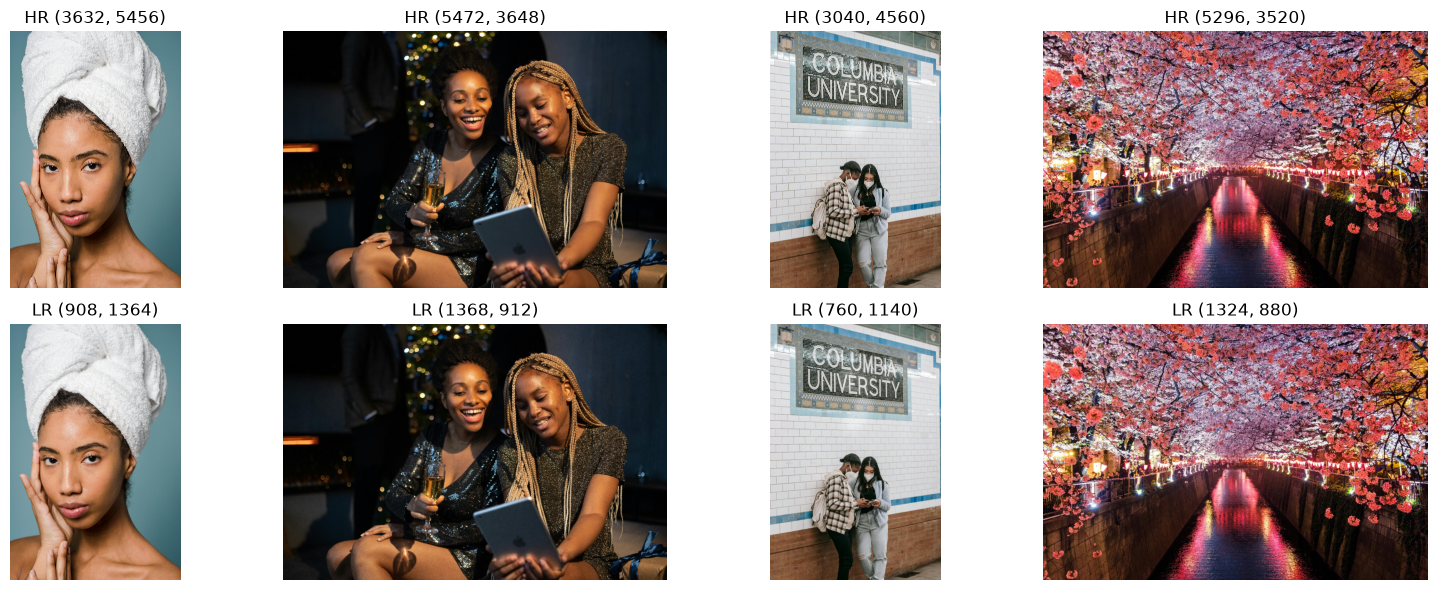

In [4]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(2, 4, figsize=(16, 6))
for column_index, row in enumerate(rows[:4]):
    axes[0, column_index].imshow(row["hr"])
    axes[0, column_index].set_title(f"HR {row['hr'].size}")
    axes[1, column_index].imshow(row["lr"])
    axes[1, column_index].set_title(f"LR {row['lr'].size}")
    axes[0, column_index].axis("off")
    axes[1, column_index].axis("off")
plt.tight_layout()
plt.show()